In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("OTT_Show_Performance_Dataset.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (1203, 8)


,Show_ID,Genre,Language,Runtime,Release_Year,Budget,Rating,Viewership
0,OTT0001,Documentary,Malayalam,141.0,2017,34.7,6.6,2.64
1,OTT0002,Thriller,Korean,62.0,2026,19.9,7.2,4.49
2,OTT0003,Crime,English,90.0,2026,18.1,5.6,7.01
3,OTT0004,Romance,English,111.0,2023,36.8,8.1,6.79
4,OTT0005,Documentary,English,150.0,2025,9.3,8.4,8.68


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1203 entries, 0 to 1202
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Show_ID       1203 non-null   object 
 1   Genre         1195 non-null   object 
 2   Language      1197 non-null   object 
 3   Runtime       1198 non-null   float64
 4   Release_Year  1203 non-null   int64  
 5   Budget        1198 non-null   float64
 6   Rating        1199 non-null   float64
 7   Viewership    1203 non-null   float64
dtypes: float64(4), int64(1), object(3)
memory usage: 75.3+ KB
None


In [ ]:
df.describe()

,Runtime,Release_Year,Budget,Rating,Viewership
count,1198.000000,1203.000000,1198.000000,1199.000000,1203.000000
mean,105.160267,2020.509559,30.602337,7.037865,6.136226
std,24.628047,3.482144,21.243529,1.007485,1.857621
min,40.000000,2015.000000,3.800000,4.000000,0.300000
25%,88.000000,2017.000000,16.325000,6.400000,4.900000
50%,105.000000,2020.000000,24.300000,7.000000,6.170000
75%,122.750000,2023.000000,38.975000,7.700000,7.390000
max,180.000000,2026.000000,151.200000,9.600000,11.550000


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Show_ID         0
Genre           8
Language        6
Runtime         5
Release_Year    0
Budget          5
Rating          4
Viewership      0
dtype: int64

Duplicate Rows:
3


In [ ]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate rows: 3
Shape after removing duplicates: (1200, 8)


In [ ]:
print(df.isnull().sum())

Show_ID         0
Genre           8
Language        6
Runtime         5
Release_Year    0
Budget          5
Rating          4
Viewership      0
dtype: int64


In [ ]:
# Fill categorical missing values with mode
df["Genre"] = df["Genre"].fillna(df["Genre"].mode()[0])
df["Language"] = df["Language"].fillna(df["Language"].mode()[0])

# Fill numerical missing values with median
df["Runtime"] = df["Runtime"].fillna(df["Runtime"].median())
df["Budget"] = df["Budget"].fillna(df["Budget"].median())
df["Rating"] = df["Rating"].fillna(df["Rating"].median())

In [ ]:
print(df.isnull().sum())

Show_ID         0
Genre           0
Language        0
Runtime         0
Release_Year    0
Budget          0
Rating          0
Viewership      0
dtype: int64


In [ ]:
print("Invalid Runtime:", (df["Runtime"] <= 0).sum())
print("Invalid Budget:", (df["Budget"] < 0).sum())
print("Invalid Rating:", ((df["Rating"] < 0) | (df["Rating"] > 10)).sum())
print("Invalid Viewership:", (df["Viewership"] < 0).sum())

Invalid Runtime: 0
Invalid Budget: 0
Invalid Rating: 0
Invalid Viewership: 0


In [ ]:
print(df.dtypes)

Show_ID          object
Genre            object
Language         object
Runtime         float64
Release_Year      int64
Budget          float64
Rating          float64
Viewership      float64
dtype: object


In [ ]:
print("Final Dataset Shape:", df.shape)

display(df.head())

Final Dataset Shape: (1200, 8)


,Show_ID,Genre,Language,Runtime,Release_Year,Budget,Rating,Viewership
0,OTT0001,Documentary,Malayalam,141.0,2017,34.7,6.6,2.64
1,OTT0002,Thriller,Korean,62.0,2026,19.9,7.2,4.49
2,OTT0003,Crime,English,90.0,2026,18.1,5.6,7.01
3,OTT0004,Romance,English,111.0,2023,36.8,8.1,6.79
4,OTT0005,Documentary,English,150.0,2025,9.3,8.4,8.68


In [ ]:
# Numerical summary
df.describe()

,Runtime,Release_Year,Budget,Rating,Viewership
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,105.174167,2020.510000,30.522250,7.035583,6.129667
std,24.574759,3.483056,21.166368,1.005170,1.849680
min,40.000000,2015.000000,3.800000,4.000000,0.300000
25%,88.000000,2017.000000,16.375000,6.400000,4.900000
50%,105.000000,2020.000000,24.300000,7.000000,6.165000
75%,122.250000,2023.000000,38.800000,7.700000,7.390000
max,180.000000,2026.000000,151.200000,9.600000,11.550000


In [ ]:
print("Average Runtime:", round(df["Runtime"].mean(), 2))
print("Average Budget:", round(df["Budget"].mean(), 2))
print("Average Rating:", round(df["Rating"].mean(), 2))
print("Average Viewership:", round(df["Viewership"].mean(), 2))

Average Runtime: 105.17
Average Budget: 30.52
Average Rating: 7.04
Average Viewership: 6.13


In [ ]:
genre_viewership = (
    df.groupby("Genre")["Viewership"]
    .mean()
    .sort_values(ascending=False)
)

print(genre_viewership)

Genre
Action         6.494063
Crime          6.453417
Sci-Fi         6.447043
Fantasy        6.372710
Comedy         6.245631
Thriller       6.160450
Drama          6.091733
Romance        6.069843
Family         5.579756
Documentary    5.419052
Name: Viewership, dtype: float64


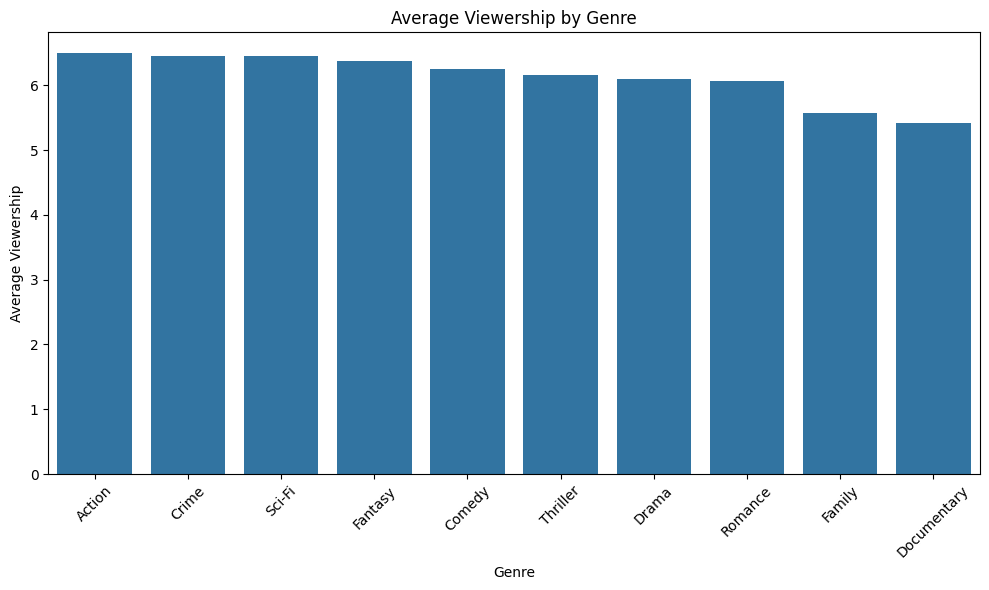

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=genre_viewership.index,
    y=genre_viewership.values
)

plt.title("Average Viewership by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Viewership")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
correlation = df["Rating"].corr(df["Viewership"])

print("Rating-Viewership Correlation:", round(correlation, 3))

Rating-Viewership Correlation: 0.423


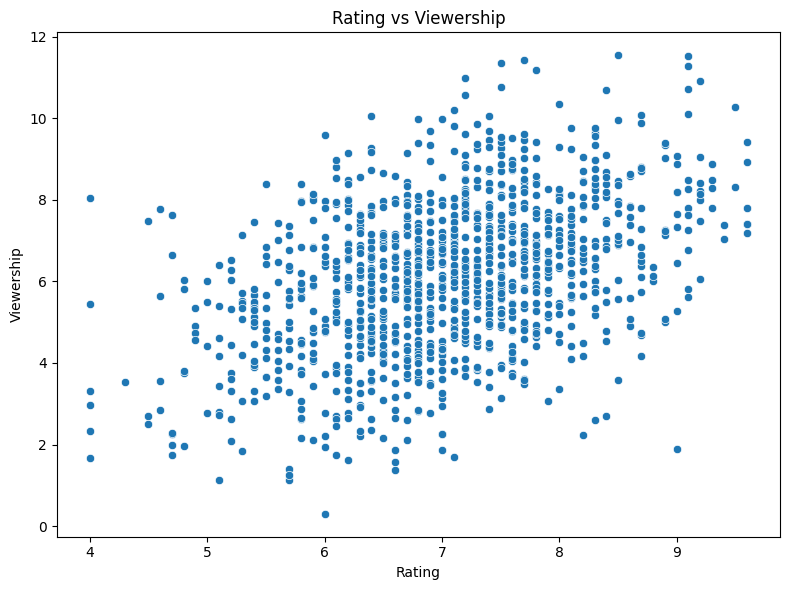

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Rating",
    y="Viewership"
)

plt.title("Rating vs Viewership")
plt.xlabel("Rating")
plt.ylabel("Viewership")
plt.tight_layout()
plt.show()

In [ ]:
language_count = df["Language"].value_counts()

print(language_count)

Language
English      302
Hindi        170
Korean       150
Spanish      147
Tamil        120
Japanese     108
Malayalam    102
Telugu       101
Name: count, dtype: int64


In [ ]:
language_viewership = (
    df.groupby("Language")["Viewership"]
    .mean()
    .sort_values(ascending=False)
)

print(language_viewership)

Language
English      6.324702
Hindi        6.199235
Telugu       6.150297
Japanese     6.149259
Spanish      6.127279
Korean       6.106200
Tamil        5.846000
Malayalam    5.766765
Name: Viewership, dtype: float64


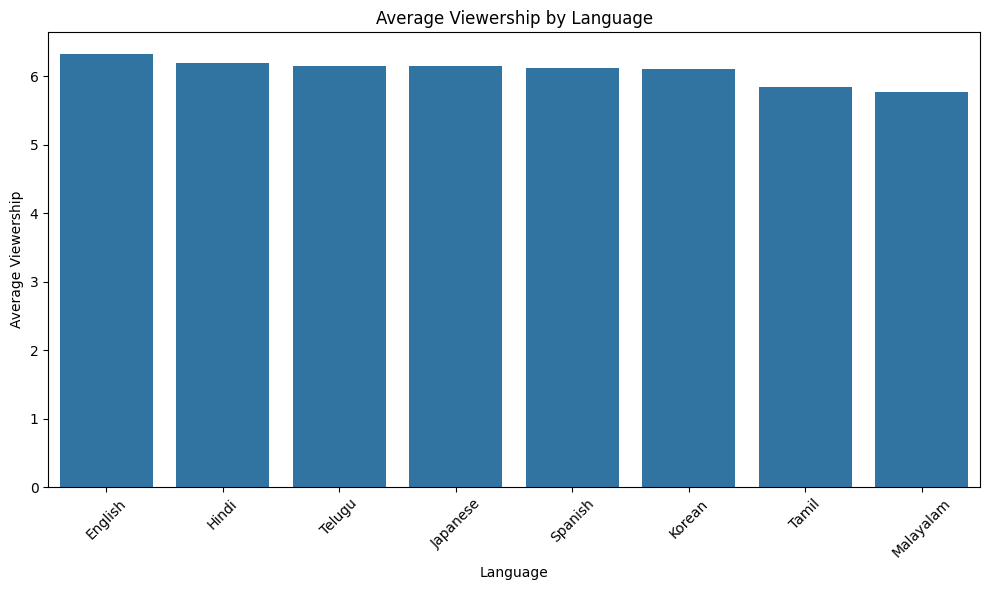

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=language_viewership.index,
    y=language_viewership.values
)

plt.title("Average Viewership by Language")
plt.xlabel("Language")
plt.ylabel("Average Viewership")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
budget_correlation = df["Budget"].corr(df["Viewership"])

print(
    "Budget-Viewership Correlation:",
    round(budget_correlation, 3)
)

Budget-Viewership Correlation: 0.188


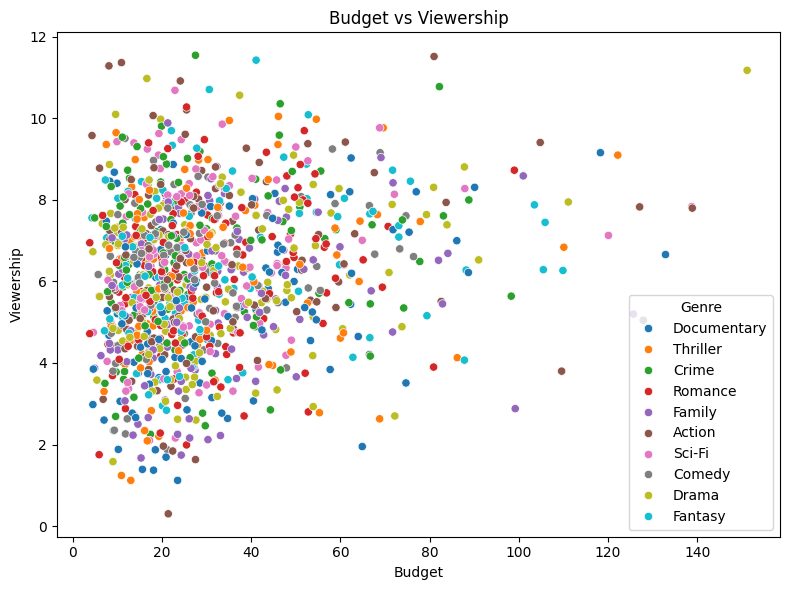

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Budget",
    y="Viewership",
    hue="Genre"
)

plt.title("Budget vs Viewership")
plt.xlabel("Budget")
plt.ylabel("Viewership")
plt.tight_layout()
plt.show()

In [ ]:
threshold = df["Viewership"].median()

print("Viewership Success Threshold:", threshold)

Viewership Success Threshold: 6.165


In [ ]:
df["Success"] = np.where(
    df["Viewership"] >= threshold,
    "Successful",
    "Less Successful"
)

In [ ]:
print(df["Success"].value_counts())

Success
Less Successful    600
Successful         600
Name: count, dtype: int64


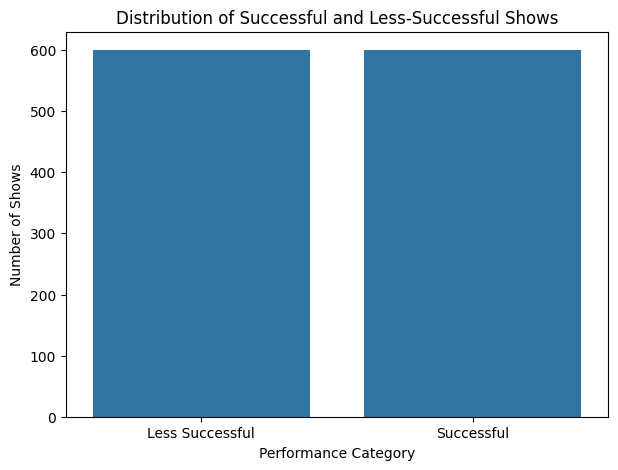

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Success"
)

plt.title("Distribution of Successful and Less-Successful Shows")
plt.xlabel("Performance Category")
plt.ylabel("Number of Shows")
plt.show()

In [ ]:
successful = df[df["Success"] == "Successful"]

print("Successful Shows:", len(successful))

print("\nAverage Rating:")
print(successful["Rating"].mean())

print("\nAverage Budget:")
print(successful["Budget"].mean())

print("\nAverage Runtime:")
print(successful["Runtime"].mean())

Successful Shows: 600

Average Rating:
7.3625

Average Budget:
34.1855

Average Runtime:
106.90166666666667


In [ ]:
X = df[
    [
        "Genre",
        "Language",
        "Runtime",
        "Release_Year",
        "Budget",
        "Rating"
    ]
]

y = df["Success"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,Genre,Language,Runtime,Release_Year,Budget,Rating
0,Documentary,Malayalam,141.0,2017,34.7,6.6
1,Thriller,Korean,62.0,2026,19.9,7.2
2,Crime,English,90.0,2026,18.1,5.6
3,Romance,English,111.0,2023,36.8,8.1
4,Documentary,English,150.0,2025,9.3,8.4



Target:


,Success
0,Less Successful
1,Less Successful
2,Successful
3,Successful
4,Successful


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 960
Testing samples: 240


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "Genre",
    "Language"
]

numeric_features = [
    "Runtime",
    "Release_Year",
    "Budget",
    "Rating"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

In [ ]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42
            )
        )
    ]
)

In [ ]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
y_pred = rf_model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
['Less Successful' 'Successful' 'Less Successful' 'Less Successful'
 'Less Successful' 'Successful' 'Successful' 'Successful'
 'Less Successful' 'Successful' 'Less Successful' 'Successful'
 'Less Successful' 'Successful' 'Less Successful' 'Less Successful'
 'Successful' 'Less Successful' 'Less Successful' 'Less Successful']


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    pos_label="Successful"
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label="Successful"
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label="Successful"
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

Accuracy : 0.6208
Precision: 0.609
Recall   : 0.675
F1 Score : 0.6403


In [ ]:
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

Accuracy : 62.08 %
Precision: 60.9 %
Recall   : 67.5 %
F1 Score : 64.03 %


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

Less Successful       0.64      0.57      0.60       120
     Successful       0.61      0.68      0.64       120

       accuracy                           0.62       240
      macro avg       0.62      0.62      0.62       240
   weighted avg       0.62      0.62      0.62       240



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Less Successful", "Successful"]
)

print(cm)

[[68 52]
 [39 81]]


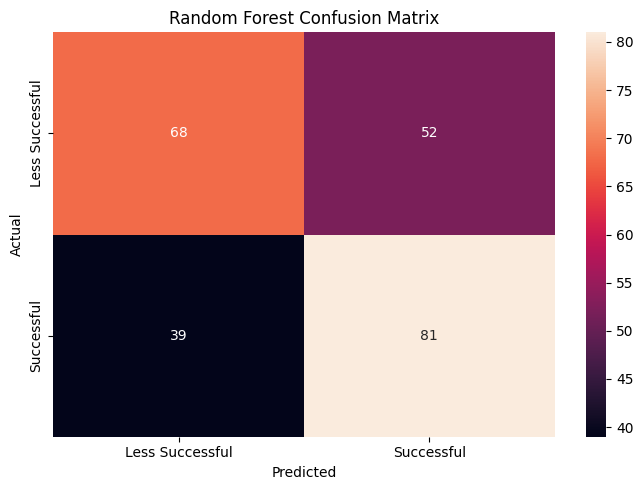

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Less Successful", "Successful"],
    yticklabels=["Less Successful", "Successful"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
rf = rf_model.named_steps["classifier"]

print("Number of trees:", len(rf.estimators_))

Number of trees: 200


In [ ]:
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

print(feature_names)

['categorical__Genre_Action' 'categorical__Genre_Comedy'
 'categorical__Genre_Crime' 'categorical__Genre_Documentary'
 'categorical__Genre_Drama' 'categorical__Genre_Family'
 'categorical__Genre_Fantasy' 'categorical__Genre_Romance'
 'categorical__Genre_Sci-Fi' 'categorical__Genre_Thriller'
 'categorical__Language_English' 'categorical__Language_Hindi'
 'categorical__Language_Japanese' 'categorical__Language_Korean'
 'categorical__Language_Malayalam' 'categorical__Language_Spanish'
 'categorical__Language_Tamil' 'categorical__Language_Telugu'
 'numeric__Runtime' 'numeric__Release_Year' 'numeric__Budget'
 'numeric__Rating']


In [ ]:
importance = rf.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
21,numeric__Rating,0.224427
20,numeric__Budget,0.197109
18,numeric__Runtime,0.167467
19,numeric__Release_Year,0.126784
10,categorical__Language_English,0.021568
11,categorical__Language_Hindi,0.017469
13,categorical__Language_Korean,0.017147
3,categorical__Genre_Documentary,0.016841
1,categorical__Genre_Comedy,0.016713
12,categorical__Language_Japanese,0.016517


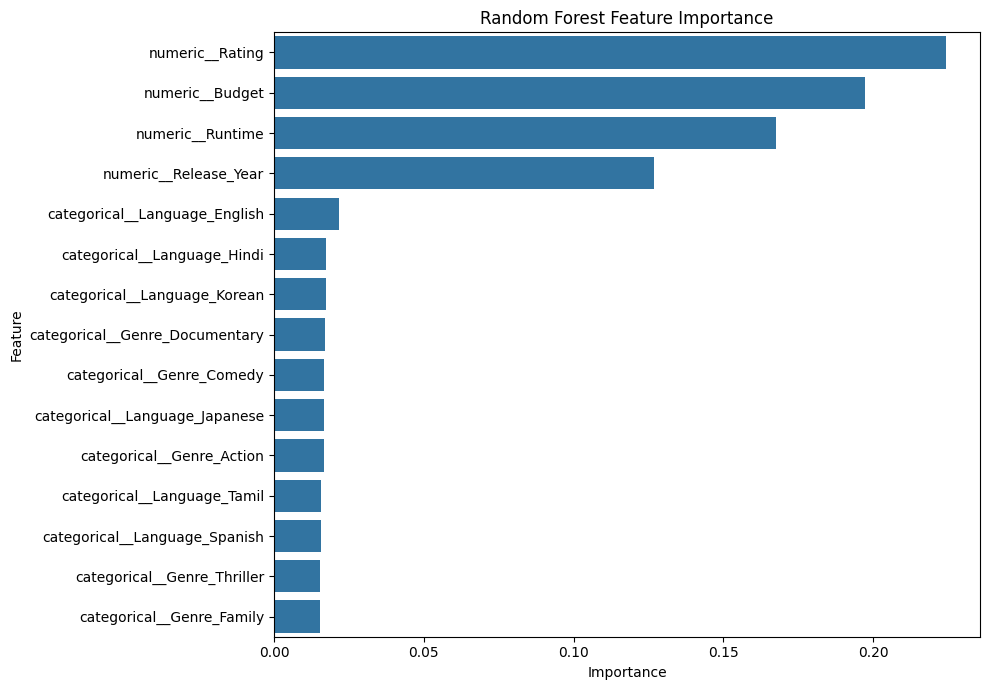

In [ ]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [ ]:
print("========== OVERALL ==========")

print("Total Shows:", len(df))
print("Average Rating:", round(df["Rating"].mean(), 2))
print("Average Budget:", round(df["Budget"].mean(), 2))
print("Average Viewership:", round(df["Viewership"].mean(), 2))

print("\n========== CORRELATIONS ==========")

print(
    "Rating vs Viewership:",
    round(df["Rating"].corr(df["Viewership"]), 3)
)

print(
    "Budget vs Viewership:",
    round(df["Budget"].corr(df["Viewership"]), 3)
)

print(
    "Runtime vs Viewership:",
    round(df["Runtime"].corr(df["Viewership"]), 3)
)

========== OVERALL ==========
Total Shows: 1200
Average Rating: 7.04
Average Budget: 30.52
Average Viewership: 6.13

========== CORRELATIONS ==========
Rating vs Viewership: 0.423
Budget vs Viewership: 0.188
Runtime vs Viewership: 0.103


In [ ]:
genre_analysis = df.groupby("Genre").agg(
    Shows=("Show_ID", "count"),
    Avg_Rating=("Rating", "mean"),
    Avg_Budget=("Budget", "mean"),
    Avg_Viewership=("Viewership", "mean")
).sort_values(
    "Avg_Viewership",
    ascending=False
)

display(genre_analysis.round(2))

,Shows,Avg_Rating,Avg_Budget,Avg_Viewership
Genre,,,,
Action,128,7.04,29.96,6.49
Crime,120,7.18,28.39,6.45
Sci-Fi,115,6.97,28.97,6.45
Fantasy,107,7.10,33.23,6.37
Comedy,103,6.99,29.41,6.25
Thriller,111,6.99,29.86,6.16
Drama,150,6.98,30.79,6.09
Romance,127,7.06,29.96,6.07
Family,123,6.96,31.53,5.58


In [ ]:
language_analysis = df.groupby("Language").agg(
    Shows=("Show_ID", "count"),
    Avg_Rating=("Rating", "mean"),
    Avg_Budget=("Budget", "mean"),
    Avg_Viewership=("Viewership", "mean")
).sort_values(
    "Avg_Viewership",
    ascending=False
)

display(language_analysis.round(2))

,Shows,Avg_Rating,Avg_Budget,Avg_Viewership
Language,,,,
English,302,7.03,30.95,6.32
Hindi,170,7.04,29.84,6.20
Telugu,101,7.04,31.82,6.15
Japanese,108,6.99,34.86,6.15
Spanish,147,7.08,30.15,6.13
Korean,150,6.99,30.90,6.11
Tamil,120,7.00,26.54,5.85
Malayalam,102,7.14,29.18,5.77


In [ ]:
success_analysis = df.groupby("Success").agg(
    Shows=("Show_ID", "count"),
    Avg_Rating=("Rating", "mean"),
    Avg_Budget=("Budget", "mean"),
    Avg_Runtime=("Runtime", "mean"),
    Avg_Viewership=("Viewership", "mean")
)

display(success_analysis.round(2))

,Shows,Avg_Rating,Avg_Budget,Avg_Runtime,Avg_Viewership
Success,,,,,
Less Successful,600,6.71,26.86,103.45,4.65
Successful,600,7.36,34.19,106.90,7.61


In [ ]:
combination_analysis = df.groupby(
    ["Genre", "Language"]
).agg(
    Shows=("Show_ID", "count"),
    Avg_Viewership=("Viewership", "mean"),
    Avg_Rating=("Rating", "mean")
).reset_index()

# Only consider combinations with at least 10 shows
combination_analysis = combination_analysis[
    combination_analysis["Shows"] >= 10
]

combination_analysis = combination_analysis.sort_values(
    "Avg_Viewership",
    ascending=False
)

display(combination_analysis.head(15).round(2))

,Genre,Language,Shows,Avg_Viewership,Avg_Rating
6,Action,Tamil,10,7.20,7.27
19,Crime,Korean,16,7.15,7.32
16,Crime,English,32,7.14,7.26
75,Thriller,Korean,11,7.14,7.13
49,Fantasy,Hindi,14,7.09,7.17
0,Action,English,34,7.01,7.10
58,Romance,Japanese,16,6.98,7.43
1,Action,Hindi,16,6.92,7.58
67,Sci-Fi,Korean,11,6.86,6.99
9,Comedy,Hindi,19,6.72,6.71
